# Present Your Solution

**Will it be an early spring?** A buy / don't-buy recommendation for fast-growing corn seeds, for a consortium of farms in western Pennsylvania.

| | |
|---|---|
| **Client question** | Every year, before the March 1 order deadline: should each farmer buy the expensive seeds for a second harvest? Each farmer decides alone, some are more cautious, and some want the chance of an early spring |
| **What we built** | A model that reads the farm's January–February weather and soil data and gives the **chance of an early spring**, with a recommendation to buy when that chance is above 20% (higher for cautious farmers) |
| **Bottom line** | The model looked useful on 1947–2010, but on the most recent 15 years (2012–2026) it earned **less than simply buying every year**. **Our recommendation: buy the seeds every year**, and keep the model as a warning signal only once it is retrained on recent years |

This notebook summarizes the project for the client. The details are in the other notebooks: *Early Spring* (framing, getting the data), *Exploration*, *Preparation* and *Training*.

In [1]:
# Imports and data
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import early_spring_prep  # noqa: F401  (must be imported before unpickling model.pkl)
from early_spring_prep import TARGET, SEED_COST, profit_per_year

train_set = pd.read_parquet("train_set.parquet")
test_set = pd.read_parquet("test_set.parquet")
with open("model.pkl", "rb") as f:
    model = pickle.load(f)          # final model (Naive Bayes) with its preprocessor, fit on 1947-2010

X_train, y_train = train_set.drop(columns=TARGET), train_set[TARGET].astype(bool)
X_test, y_test = test_set.drop(columns=TARGET), test_set[TARGET].astype(bool)
GREEN, GRAY, RED, BLUE = "#2e8b57", "#8c8c8c", "#b04a4a", "#4c72b0"

## 1. The business problem

* Seeds cost about **1/5 of the revenue** of the extra harvest and expire, so they can't be kept for next year.
* **Buy and spring is early:** +0.8 R (R = revenue of the extra harvest). **Buy and it isn't:** −0.2 R. **Don't buy:** 0.
* So buying pays off on average whenever the chance of an early spring is **above 20%**: one early spring in five purchases breaks even (confirmed by the client). A wasted purchase costs a quarter of what a missed early spring costs.
* The client added two things: **"we need to do better than break even"**, and each purchase also causes **extra wear and tear** on equipment and land, so the real break-even is a bit above 20%.
* The decision is made by **each farmer in the consortium**, and some are more cautious than others.
* "Early spring" (client's definition): the seeds can be planted by May 1 and the 10 days after planting have soil ≥ 50 °F on average, air never below 30 °F, average air ≥ 40 °F, and no snow on the ground.

We measure every strategy by **profit per year** (in units of R), not accuracy: in the older years "never buy" is right ~80% of the time and earns nothing.

## 2. The data and the most important fact about it

* **Farm data (from the client):** daily air temperature, snowfall, snow depth and 3-inch soil temperature/moisture, Jan 1 – end of Feb, 1947–2026. Turned into one row per year (e.g. February snow-cover days, February mean air temperature).
* **Two outside sources (NOAA):** El Niño (ONI) and Arctic Oscillation (AO) indices from the winter before.
* **Punxsutawney Phil's** Feb 2 call.
* 72 usable years: **1947–2010 to build the model (57 years)**, **2012–2026 to test it (15 years)**, kept hidden until the very end.

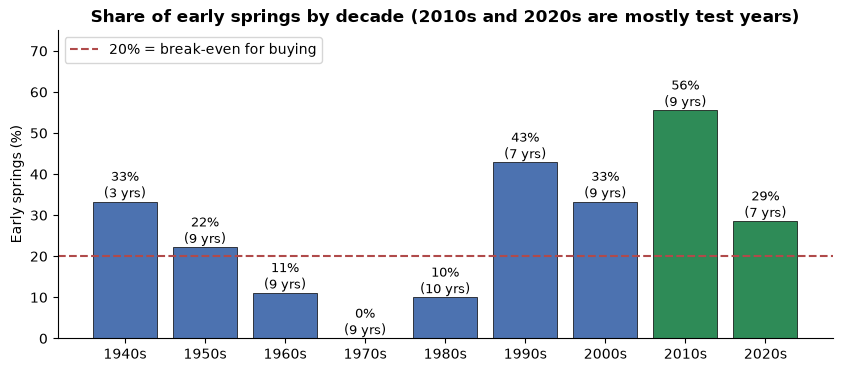

Early springs: training years 19% (11 of 57), test years 47% (7 of 15)


In [2]:
# Early springs have become far more common
years = pd.concat([train_set[["year", TARGET]].assign(part="training"),
                   test_set[["year", TARGET]].assign(part="test")])
by_decade = years.groupby(years["year"] // 10 * 10)[TARGET].agg(["mean", "count"])

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(by_decade.index.astype(str) + "s", by_decade["mean"] * 100,
              color=[BLUE if d < 2010 else GREEN for d in by_decade.index], edgecolor="black", linewidth=0.5)
for bar, (_, r) in zip(bars, by_decade.iterrows()):
    ax.annotate(f"{r['mean']:.0%}\n({int(r['count'])} yrs)", (bar.get_x() + bar.get_width() / 2, r["mean"] * 100),
                xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
ax.axhline(SEED_COST * 100, color=RED, linestyle="--", label="20% = break-even for buying")
ax.set_ylabel("Early springs (%)")
ax.set_ylim(0, 75)
ax.set_title("Share of early springs by decade (2010s and 2020s are mostly test years)", fontweight="bold")
ax.legend(loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

print(f"Early springs: training years {y_train.mean():.0%} ({y_train.sum()} of {len(y_train)}), "
      f"test years {y_test.mean():.0%} ({y_test.sum()} of {len(y_test)})")

**This is the key fact of the whole project.** Early springs went from rare (none in the 1970s, about 1 in 5 over 1947–2010) to almost every other year since 2012. Because buying only needs a 1-in-5 chance to pay off, in today's climate the odds favor buying almost every year.

## 3. What we learned from the training years (1947–2010)

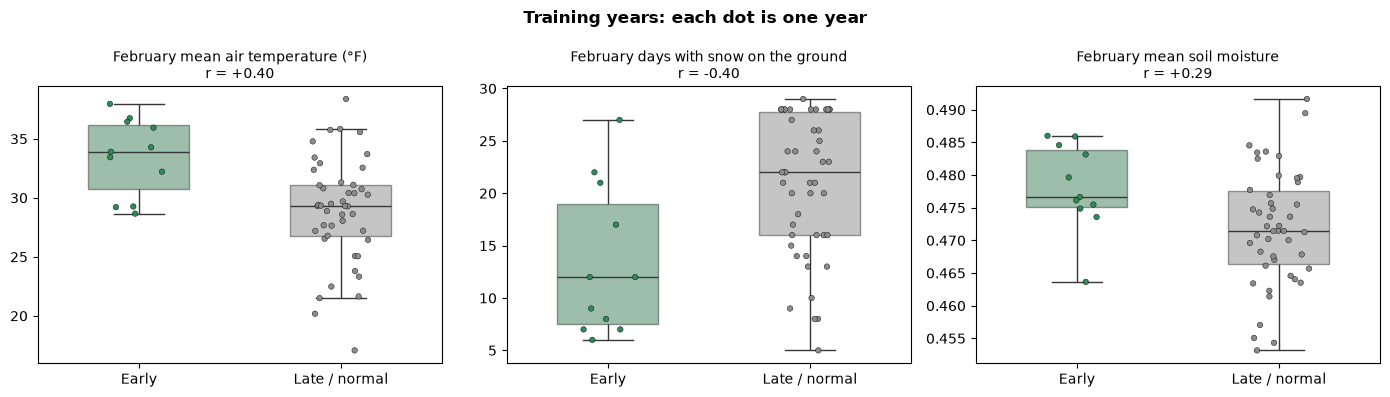

In [3]:
# What separated early springs from the others in 1947-2010
show = {"air_feb": "February mean air temperature (°F)", "snow_days": "February days with snow on the ground",
        "soil_moisture": "February mean soil moisture"}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
groups = np.where(y_train, "Early", "Late / normal")
for ax, (col, label) in zip(axes, show.items()):
    sns.boxplot(x=groups, y=X_train[col].astype(float), order=["Early", "Late / normal"], hue=groups,
                palette={"Early": GREEN, "Late / normal": GRAY}, width=0.5, ax=ax, fliersize=0, boxprops={"alpha": 0.5})
    sns.stripplot(x=groups, y=X_train[col].astype(float), order=["Early", "Late / normal"], hue=groups,
                  palette={"Early": GREEN, "Late / normal": GRAY}, size=4, jitter=0.15, ax=ax, edgecolor="black", linewidth=0.3)
    r = X_train[col].astype(float).corr(y_train.astype(float))
    ax.set_title(f"{label}\nr = {r:+.2f}", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Training years: each dot is one year", fontweight="bold")
plt.tight_layout()
plt.show()

In 1947–2010, **warmer, less snowy Februaries** were followed by early springs more often, and the soil was slightly wetter (thawed). No single feature separated the years cleanly (the best correlation is about 0.4), so we combined them in a model.

Other findings from exploration and preparation:

* **Phil is not useful.** In the training years he called an early spring 9 times and was right once (11%), below the 20% needed to break even.
* **El Niño / Arctic Oscillation indices and February soil temperature added nothing** in the training years (a random forest ranked them no better than a column of random noise).
* **Fewer features worked better.** With only 57 years and 11 early springs, extra features made the models memorize the past instead of predicting new years.

## 4. The approach

1. **Prepare:** fill the few missing values (e.g. February 2004 has no air temperatures) with the median, scale the features, choose a small set of features.
2. **Compare 7 model types** (logistic regression, k-nearest neighbors, SVM, naive Bayes, random forest, gradient boosting, and a "base-rate" dummy), all scored on **profit per year** with repeated cross-validation (each model fit 50 times on different 80/20 splits of the training years).
3. **Fine-tune** 5 of them, preprocessing and model settings together (11–20 settings each), scoring on profit, and build a voting ensemble.
4. **Pick the final model with a rule fixed in advance** (highest cross-validated profit) and test it **once** on 2012–2026, buying whenever P(early spring) > 0.2.

The final model is a **Gaussian Naive Bayes** classifier (all of the tuned models were within noise of each other).

## 5. Results

In [4]:
# Test years: the final model vs. the simple strategies
p_test = model.predict_proba(X_test)[:, 1]
buy = p_test > SEED_COST
phil_test = X_test["phil_early"].fillna(False).astype(bool)
phil_train = X_train["phil_early"].fillna(False).astype(bool)

results = pd.DataFrame({
    "Training years 1947-2010 (cross-validated)": {
        "Our model": 0.072,                                    # from the Training notebook (repeated CV)
        "Always buy": profit_per_year(y_train, np.ones(len(y_train))),
        "Never buy": 0.0,
        "Follow Phil": profit_per_year(y_train, phil_train),
        "Perfect foresight": profit_per_year(y_train, y_train)},
    "Test years 2012-2026": {
        "Our model": profit_per_year(y_test, buy),
        "Always buy": profit_per_year(y_test, np.ones(len(y_test))),
        "Never buy": 0.0,
        "Follow Phil": profit_per_year(y_test, phil_test),
        "Perfect foresight": profit_per_year(y_test, y_test)},
}).round(3)
results

,Training years 1947-2010 (cross-validated),Test years 2012-2026
Our model,0.072,0.107
Always buy,-0.007,0.267
Never buy,0.000,0.000
Follow Phil,-0.014,0.200
Perfect foresight,0.154,0.373


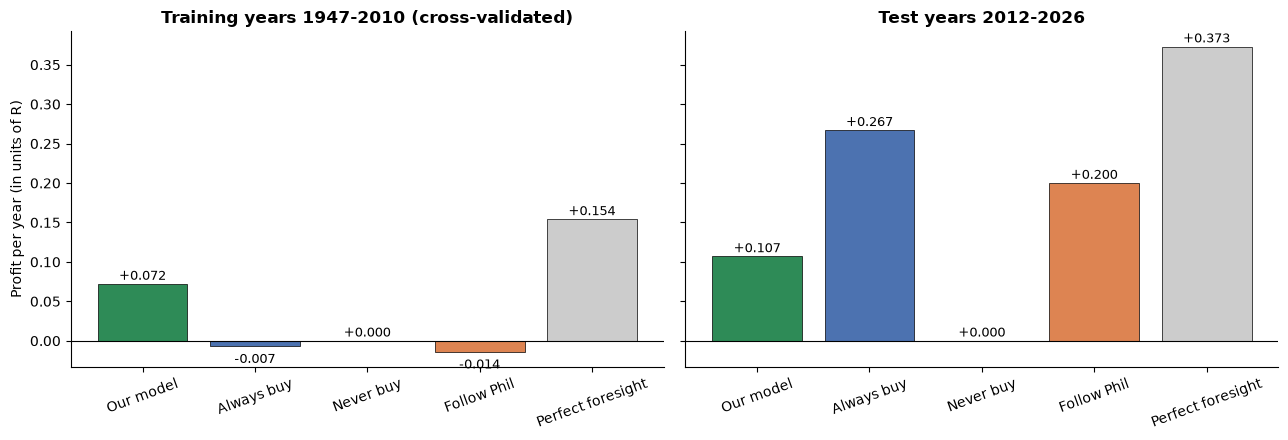

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
colors = {"Our model": GREEN, "Always buy": BLUE, "Never buy": GRAY, "Follow Phil": "#dd8452", "Perfect foresight": "#cccccc"}
for ax, col in zip(axes, results.columns):
    vals = results[col]
    ax.bar(vals.index, vals.values, color=[colors[i] for i in vals.index], edgecolor="black", linewidth=0.5)
    for i, v in enumerate(vals.values):
        ax.annotate(f"{v:+.3f}", (i, v), xytext=(0, 3 if v >= 0 else -12), textcoords="offset points", ha="center", fontsize=9)
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(col, fontweight="bold")
    ax.tick_params(axis="x", rotation=20)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Profit per year (in units of R)")
plt.tight_layout()
plt.show()

* **In the training years** the model looked worthwhile: about **+0.07 R per year**, while every simple strategy earned about zero (early springs were just below the 20% break-even, so always buying roughly broke even).
* **In the test years it did not hold up.** The model earned **+0.09 R per year**, but simply **buying every year earned +0.27 R**, and even following Phil (+0.20) did better. Perfect foresight would have earned +0.37 R.

In [6]:
# Year by year: what the model said and what happened
by_year = pd.DataFrame({
    "year": test_set["year"],
    "Feb air temp (°F)": X_test["air_feb"].astype(float).round(1),
    "Feb snow days": X_test["snow_days"].astype(float).astype(int),
    "P(early)": p_test.round(2),
    "decision": np.where(buy, "buy", "don't buy"),
    "early spring?": np.where(y_test, "yes", "no"),
    "profit (R)": np.where(buy, np.where(y_test, 1 - SEED_COST, -SEED_COST), 0.0),
})
by_year["vs. always buy"] = by_year["profit (R)"] - np.where(y_test, 1 - SEED_COST, -SEED_COST)
by_year.set_index("year")

,Feb air temp (°F),Feb snow days,P(early),decision,early spring?,profit (R),vs. always buy
year,,,,,,,
2012,34.0,6,1.00,buy,yes,0.8,0.0
2013,27.0,11,0.00,don't buy,yes,0.0,-0.8
2014,22.1,28,0.00,don't buy,no,0.0,0.2
2015,16.3,26,0.00,don't buy,yes,0.0,-0.8
2016,31.0,11,0.64,buy,yes,0.8,0.0
2017,36.9,7,1.00,buy,no,-0.2,0.0
2018,35.4,13,0.00,don't buy,no,0.0,0.2
2019,30.9,12,0.71,buy,yes,0.8,0.0
2020,32.9,7,1.00,buy,no,-0.2,0.0


The table shows where the money went (read the `vs. always buy` column):

* The model said **"don't buy" in 4 early-spring years** (2013, 2015, 2024, 2025), each a missed 0.8 R. 2015 was the coldest, snowiest February of the period and was still early. 2024 had a warm, almost snow-free February and the model still gave it a very low probability.
* It saved money in only **3 years** by not buying (2014, 2021, 2026: +0.2 R each).
* It bought in **5 years that were not early** (2017, 2018, 2020, 2022, 2023), mostly warm Februaries, which is exactly the pattern that used to mean an early spring.

Missing one early spring costs as much as wasting the seeds four times, so the 4 misses wipe out everything the model saved.

### What different farmers would have done

The farmers in the consortium decide on their own, and some are more cautious. A cautious farmer waits for a higher chance of an early spring before buying (for example 30% or 40% instead of the 20% break-even, which also covers wear and tear). The table shows what each attitude would have earned on 2012–2026 by following the model, compared with simply buying every year.

In [7]:
attitudes = {"Standard (buy if chance > 20%)": 0.2, "Cautious (> 30%)": 0.3, "Very cautious (> 40%)": 0.4}
rows = {name: {"years bought": int((p_test > t).sum()),
               "early springs caught": int(((p_test > t) & y_test).sum()),
               "profit per year (R)": profit_per_year(y_test, p_test > t)}
        for name, t in attitudes.items()}
rows["Always buy (our recommendation)"] = {"years bought": len(y_test), "early springs caught": int(y_test.sum()),
                                           "profit per year (R)": profit_per_year(y_test, np.ones(len(y_test)))}
pd.DataFrame(rows).T.astype({"years bought": int, "early springs caught": int}).round(3)

,years bought,early springs caught,profit per year (R)
Standard (buy if chance > 20%),7,3,0.107
Cautious (> 30%),7,3,0.107
Very cautious (> 40%),7,3,0.107
Always buy (our recommendation),15,7,0.267


Being more cautious with this model does not help: a higher threshold means buying in fewer years and missing more early springs, and each missed one costs 0.8 R. With early springs now happening about half the time, **buying every year beats every threshold, for cautious and standard farmers alike.**

## 6. Why the model did not carry over

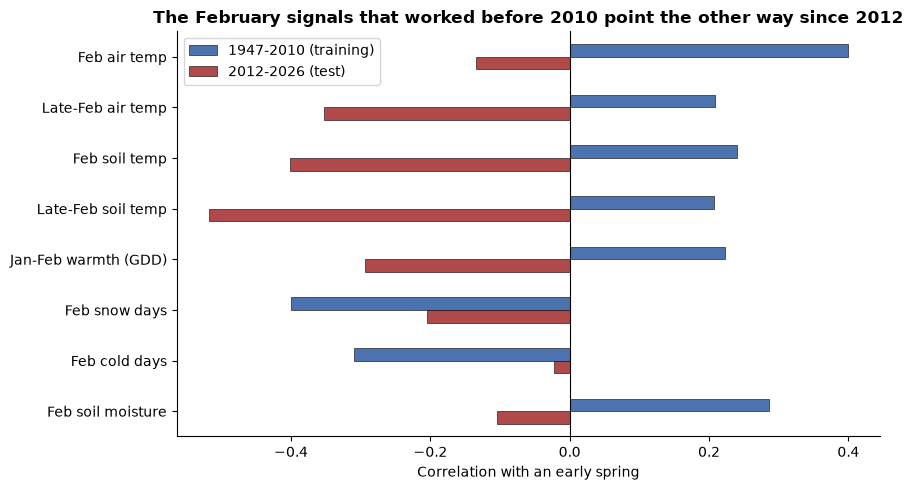

,1947-2010 (training),2012-2026 (test)
Feb air temp,0.40,-0.13
Late-Feb air temp,0.21,-0.35
Feb soil temp,0.24,-0.40
Late-Feb soil temp,0.21,-0.52
Jan-Feb warmth (GDD),0.22,-0.29
Feb snow days,-0.40,-0.20
Feb cold days,-0.31,-0.02
Feb soil moisture,0.29,-0.10


In [8]:
cols = ["air_feb", "air_feb_late", "soil_feb", "soil_feb_late", "gdd", "snow_days", "cold_days", "soil_moisture"]
names = {"air_feb": "Feb air temp", "air_feb_late": "Late-Feb air temp", "soil_feb": "Feb soil temp",
         "soil_feb_late": "Late-Feb soil temp", "gdd": "Jan-Feb warmth (GDD)", "snow_days": "Feb snow days",
         "cold_days": "Feb cold days", "soil_moisture": "Feb soil moisture"}
cmp = pd.DataFrame({
    "1947-2010 (training)": X_train[cols].astype(float).corrwith(y_train.astype(float)),
    "2012-2026 (test)": X_test[cols].astype(float).corrwith(y_test.astype(float)),
}).rename(index=names)

ax = cmp.plot.barh(figsize=(9, 5), color=[BLUE, RED], edgecolor="black", linewidth=0.4)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Correlation with an early spring")
ax.set_title("The February signals that worked before 2010 point the other way since 2012", fontweight="bold")
ax.invert_yaxis()
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
cmp.round(2)

The model learned "warm, snow-free February → early spring" from 1947–2010. Since 2012 that relationship has **disappeared or reversed**: February warmth and soil temperature now have *negative* correlations with an early spring. Cold, snowy Februaries like 2015 were followed by early springs, and warm ones like 2017 and 2023 were not.

A likely explanation (which we cannot prove with 15 years): springs have warmed so much that late-March and April weather now decides the outcome, and that is not visible in February data. **This is a case of the world changing**, not of a bug in the model.

**Caveat:** 15 test years with 7 early springs is a small sample. The exact numbers would change a lot with a few different years, but the main message, that the early-spring rate is now far above the 20% break-even, is robust.

## 7. Recommendation to the client

1. **Buy the seeds every year, for every farmer, under the current climate.** Since 2012 early springs have happened in about half the years, far above the 1-in-5 needed to break even. Always buying earned about **+0.27 R per year** on 2012–2026: clearly better than break-even, as the client asked, even after allowing for some wear and tear. It also beat our model (+0.09) and Phil (+0.20).
2. **For cautious farmers:** the same advice holds. Even if wear and tear pushed the real break-even up to 1 good year in 3 or 4, the recent early-spring rate (about 1 in 2) is still well above it.
3. **Don't rely on Punxsutawney Phil or on February weather** to decide. Neither predicted the recent springs.
4. **Revisit this every year.** If early springs became rare again (below roughly 1 in 4 years for several years in a row), the decision should be reconsidered, and cautious farmers should be the first to stop buying.
5. **If the model is kept:** retrain it every May on the most recent years only (or weight recent years more), add information closer to planting time (such as NOAA's late-February outlook for March–April), and **check that its probabilities are trustworthy** before giving them to farmers (see limitations). It should be used only as a warning signal for a clearly bad year, not to skip buying in a normal one.

## 8. Limitations

* **Very little data:** 57 training years with 11 early springs, so all cross-validation scores have a large spread (±0.05 R per year).
* **The climate changed between the training and test periods**, which no model trained only on the past can fully handle. The client confirmed every year was labeled with the same rules, so this is a real change in the weather, not in the labels.
* **The model's probabilities are too extreme to show farmers as they are.** Some farmers asked for the chance of an early spring, but the final model (naive Bayes) often says 0% or over 90%. On the test years it gave 2024 almost 0% and it was an early spring, and gave 2017 about 97% and it was not. Its probabilities should be calibrated (and checked on training years) before farmers rely on them.
* **Wear and tear is not in the numbers.** Profit uses the seed cost only (0.2 R per purchase). The real cost per purchase is a bit higher, which makes every buying strategy, including ours, slightly less profitable than shown.
* **Data gaps:** El Niño / AO indices start in 1950, and February 2004 has no air temperatures. These were filled with medians.